### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [19]:
data = pd.read_csv('data/coupons.csv')

In [20]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [21]:
missing_values = data.isnull().sum()
print(missing_values[missing_values > 0])

car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
dtype: int64


3. Decide what to do about your missing data -- drop, replace, other...

In [22]:
# Drop the 'car' column entirely
data = data.drop(columns=['car'])

# Drop the remaining rows that contain missing values
data = data.dropna()

# Verify that 0 missing values remain
print("Max missing values:", data.isnull().sum().max())

Max missing values: 0


4. What proportion of the total observations chose to accept the coupon?



In [23]:
proportion_accepted = data['Y'].mean()
print(f"Proportion of accepted coupons: {proportion_accepted:.2%}")

Proportion of accepted coupons: 56.93%


5. Use a bar plot to visualize the `coupon` column.

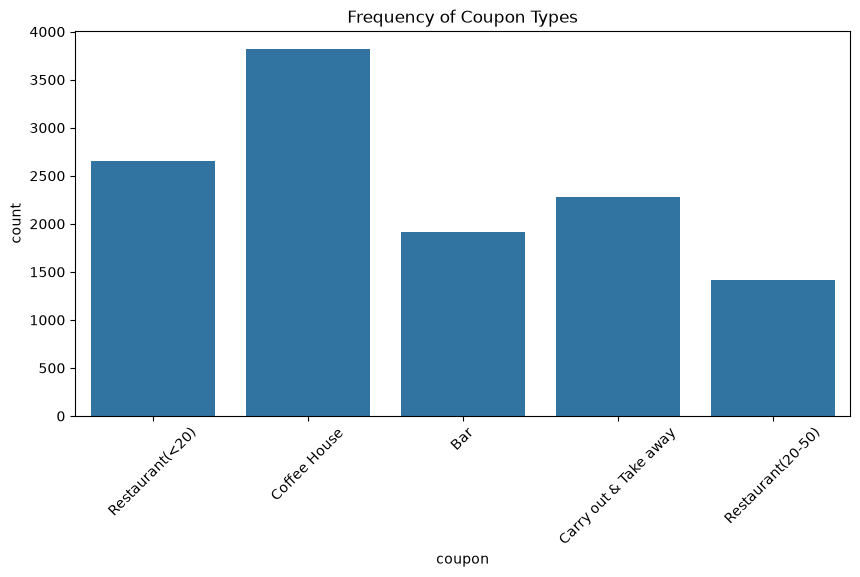

In [24]:
plt.figure(figsize=(10, 5))
sns.countplot(data=data, x='coupon')
plt.title('Frequency of Coupon Types')
plt.xticks(rotation=45) # Rotates x-axis labels to prevent text overlap
plt.show()

6. Use a histogram to visualize the temperature column.

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


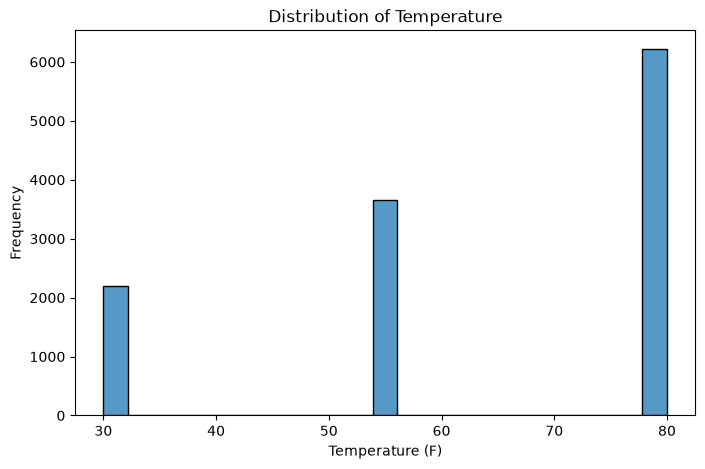

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x='temperature')
plt.title('Distribution of Temperature')
plt.xlabel('Temperature (F)')
plt.ylabel('Frequency')
plt.show()

2. What proportion of bar coupons were accepted?


In [26]:
# Filter the dataframe for only bar coupons
bar_coupons = data[data['coupon'] == 'Bar']

# Calculate the mean of the 'Y' column for this subset
proportion_bar_accepted = bar_coupons['Y'].mean()

print(f"Proportion of bar coupons accepted: {proportion_bar_accepted:.2%}")

Proportion of bar coupons accepted: 41.19%


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [27]:
# Filter the data for only bar coupons
bar_coupons = data[data['coupon'] == 'Bar']

# Define the category groups based on the dataset's string values
three_or_fewer = ['never', 'less1', '1~3']
more_than_three = ['4~8', 'gt8']

# Calculate the acceptance rates for each group
rate_three_or_fewer = bar_coupons[bar_coupons['Bar'].isin(three_or_fewer)]['Y'].mean()
rate_more = bar_coupons[bar_coupons['Bar'].isin(more_than_three)]['Y'].mean()

print(f"Acceptance rate (3 or fewer times): {rate_three_or_fewer:.2%}")
print(f"Acceptance rate (More than 3 times): {rate_more:.2%}")

Acceptance rate (3 or fewer times): 37.27%
Acceptance rate (More than 3 times): 76.17%


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [28]:
# Filter for bar coupons (if not already done in the same cell)
bar_coupons = data[data['coupon'] == 'Bar']

# Define the target string categories
frequent_bar_goers = ['1~3', '4~8', 'gt8']
under_26 = ['below21', '21', 'below 21', '21 to 25'] 

# Create a boolean mask for the target group
target_mask = (
    (bar_coupons['Bar'].isin(frequent_bar_goers)) &
    (~bar_coupons['age'].isin(under_26))
)

# Calculate the mean acceptance rate (Y=1) for both groups
rate_target_group = bar_coupons[target_mask]['Y'].mean()
rate_others = bar_coupons[~target_mask]['Y'].mean()

print(f"Target Group Acceptance Rate: {rate_target_group:.2%}")
print(f"All Others Acceptance Rate: {rate_others:.2%}")

# Answer whether there is a difference
difference = rate_target_group - rate_others
print(f"Difference: {difference:.2%}")

Target Group Acceptance Rate: 68.98%
All Others Acceptance Rate: 33.77%
Difference: 35.21%


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [29]:
# Create a boolean mask for the target group
# Note: Using the exact 'passanger' spelling from the dataset header
target_mask = (
    (bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])) &
    (bar_coupons['passanger'] != 'Kid(s)') &
    (bar_coupons['occupation'] != 'Farming Fishing & Forestry')
)

# Calculate the mean acceptance rate for the target group vs. everyone else
rate_target = bar_coupons[target_mask]['Y'].mean()
rate_others = bar_coupons[~target_mask]['Y'].mean()

print(f"Target Group Acceptance Rate: {rate_target:.2%}")
print(f"All Others Acceptance Rate: {rate_others:.2%}")

# Display the difference
print(f"Difference: {rate_target - rate_others:.2%}")

Target Group Acceptance Rate: 70.94%
All Others Acceptance Rate: 29.79%
Difference: 41.15%


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [30]:
# 1. Define the categories based on the dataset's specific string formats
frequent_bar = ['1~3', '4~8', 'gt8']
under_30 = ['below21', '21', '26', 'below 21', '21 to 25', '26 to 30'] # Covers variations
frequent_cheap_rest = ['4~8', 'gt8']
income_under_50k = ['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999']

# 2. Build the three distinct conditional masks
cond1 = (
    (bar_coupons['Bar'].isin(frequent_bar)) & 
    (bar_coupons['passanger'] != 'Kid(s)') & 
    (bar_coupons['maritalStatus'] != 'Widowed')
)

cond2 = (
    (bar_coupons['Bar'].isin(frequent_bar)) & 
    (bar_coupons['age'].isin(under_30))
)

cond3 = (
    (bar_coupons['RestaurantLessThan20'].isin(frequent_cheap_rest)) & 
    (bar_coupons['income'].isin(income_under_50k))
)

# 3. Combine them with the OR (|) operator
combined_mask = cond1 | cond2 | cond3

# 4. Calculate and compare the acceptance rates
rate_target_group = bar_coupons[combined_mask]['Y'].mean()
rate_others = bar_coupons[~combined_mask]['Y'].mean()

print(f"Target Groups Acceptance Rate: {rate_target_group:.2%}")
print(f"All Others Acceptance Rate: {rate_others:.2%}")
print(f"Difference: {rate_target_group - rate_others:.2%}")

Target Groups Acceptance Rate: 58.71%
All Others Acceptance Rate: 29.99%
Difference: 28.72%


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

Based on the previous observations, drivers who accept bar coupons are most likely to be younger adults who already frequent bars and are not driving with children. The data suggests that preexisting habits (going to bars more than once a month) and immediate driving context (lack of child passengers) are the strongest predictors of accepting a bar coupon. In contrast, older drivers, those who rarely visit bars, or those traveling with kids are significantly more likely to reject the offer.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

In [31]:
coffee_coupons = data[data['coupon'] == 'Coffee House']

In [32]:
overall_coffee_rate = coffee_coupons['Y'].mean()
print(f"Overall Coffee House acceptance rate: {overall_coffee_rate:.2%}")

Overall Coffee House acceptance rate: 49.63%


In [33]:
time_rates = coffee_coupons.groupby('time')['Y'].mean().sort_values(ascending=False)
print("Acceptance rates by time of day:")
print(time_rates)

Acceptance rates by time of day:
time
10AM    0.634772
2PM     0.545455
7AM     0.440000
10PM    0.429078
6PM     0.412272
Name: Y, dtype: float64


In [34]:
habit_rates = coffee_coupons.groupby('CoffeeHouse')['Y'].mean().sort_values(ascending=False)
print("Acceptance rates by prior coffee house visits:")
print(habit_rates)

Acceptance rates by prior coffee house visits:
CoffeeHouse
4~8      0.682446
gt8      0.657895
1~3      0.647694
less1    0.480989
never    0.175223
Name: Y, dtype: float64


In [35]:
# Compare drivers on the road mid-day who already frequent coffee houses against all others
target_mask = (
    (coffee_coupons['time'].isin(['10AM', '2PM'])) &
    (coffee_coupons['CoffeeHouse'].isin(['1~3', '4~8', 'gt8']))
)

rate_target = coffee_coupons[target_mask]['Y'].mean()
rate_others = coffee_coupons[~target_mask]['Y'].mean()

print(f"Target Group (Mid-day + Frequent Visitor) Rate: {rate_target:.2%}")
print(f"All Others Acceptance Rate: {rate_others:.2%}")
print(f"Difference: {rate_target - rate_others:.2%}")

Target Group (Mid-day + Frequent Visitor) Rate: 77.20%
All Others Acceptance Rate: 42.49%
Difference: 34.70%
